# 02b – Classify: logistic regression

The office needs to make a decision yes or no: Is this house above 450 heating index? (so that we should contact the owner) Thus is this notebook istead of predicting in the form index number through ridge and lasso, we predict the probability of being above 450 and rank houses by it, and put the top 20% on the owners of the energy office contact list. We judge the model by how many houses on that list are actually above 450.

Thus an analyisis check is determined: does classification predicting "yes/no" rank houses better than number?







In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, ConfusionMatrixDisplay)

from config import THRESHOLD
from pipeline import split_xy, build_preprocessor
from metrics import share_above_in_top, evaluate

## 1. Load the data and put the test data away
Use the exact same data as fold 02_estimate. The test data is never touched in logistic regression.

In [52]:
data = pd.read_csv(processed / "building_clean.csv")       # one row per building
split = pd.read_csv(processed / "split.csv")               # EGID, test, fold
data = data.merge(split, on="EGID", how="inner", validate="one_to_one")   # attach test flag + fold

train = data[data["test"] == False].reset_index(drop=True) # only cross-validation buildings
train["fold"] = train["fold"].astype(int)                  # 0.0-4.0 -> 0-4

X, y, is_house, groups = split_xy(train)                   # features, index, house flag, groups
folds = train["fold"].to_numpy()                           # fold number of every building
print("Buildings:", len(train), "| houses:", int(is_house.sum()))

Buildings: 12710 | houses: 1171


## 2. Check the label, to ensure classes are balanced enough 
Classification learns from "above 450: yes/no", as a value above 450 counts as a problem case. Also check that both classes are common enough. This share is also the random reference.

In [53]:
y_class = y > THRESHOLD                                    # True = above 450
print("Houses above 450:", round(y_class[is_house].mean() * 100, 1), "%")   # about 38%
print("All buildings above 450:", round(y_class.mean() * 100, 1), "%")      # about 29%

Houses above 450: 38.0 %
All buildings above 450: 29.0 %


About 38% of houses are above 450, which is balanced enough, so no class weights are needed.

## 3. Cross-validation of logistic regression

It trains logistic regression 5 times, predicts the left-out buildings, and measures how many houses above 450 end up in the top 20%. Then it picks the setting that does best.

In [63]:
def cv_logistic(C, expert_rule):
    # every building gets a probability from the model that did NOT see it
    p_oof = np.zeros(len(y))
    for k in range(5):
        is_val = folds == k
        is_tr = folds != k
        prep = build_preprocessor(expert_rule=expert_rule)
        prep.fit(X[is_tr], y[is_tr])
        X_tr_s = prep.transform(X[is_tr])
        X_val_s = prep.transform(X[is_val])
        lrc = LogisticRegression(C=C, max_iter=5000).fit(X_tr_s, y_class[is_tr])
        p_oof[is_val] = lrc.predict_proba(X_val_s)[:, 1]
    return p_oof

def top20_per_fold(p):
    # selection measure on the houses of each fold
    scores = []
    for k in range(5):
        m = (folds == k) & is_house
        scores.append(share_above_in_top(y[m], p[m], top=0.20))
    return np.array(scores)

C_values = [0.001, 0.01, 0.1, 1, 10, 100]
rows = []
for expert_rule in [True, False]:
    for C in C_values:
        s = top20_per_fold(cv_logistic(C, expert_rule))
        rows.append({"expert_rule": expert_rule, "C": C,
                     "top 20%: above 450 (%)": round(s.mean() * 100, 1),
                     "± SE": round(s.std(ddof=1) / np.sqrt(5) * 100, 1)})
tuning = pd.DataFrame(rows)
display(tuning)

best = tuning.sort_values("top 20%: above 450 (%)", ascending=False).iloc[0]
best_C, best_er = best["C"], bool(best["expert_rule"])
print("Best: C =", best_C, "| expert rule:", best_er)


,expert_rule,C,top 20%: above 450 (%),± SE
0,True,0.001,53.2,4.1
1,True,0.010,51.9,3.6
2,True,0.100,52.8,2.5
3,True,1.000,53.2,2.7
4,True,10.000,53.6,2.9
5,True,100.000,53.6,2.9
6,False,0.001,49.8,1.6
7,False,0.010,53.2,3.4
8,False,0.100,51.5,2.6
9,False,1.000,53.6,2.0


Best: C = 10.0 | expert rule: False


## 4. Judge the chosen model


Get the predictions and main scores of the logistic regression model: C=10, without expert rule (from Step 3)
Now we check how good it really is, from three sides:

- **4a. Main job:** How many problem houses at the top 20% of the list?
- **4b. Mistakes:** as a yes/no rule, which mistakes does it make?
- **4c. Competition:** is it better than the six regression models, including linear regression, ridge and lasso, each with and without the expert rule?

Every house is judged by a model that did not see it (out of fold). The test set is not used.

### 4a. Main job: are the problem houses at the top of the list?

Step by step:
1. Our model gives every house a number between 0 and 1: the **chance of being above 450**.
2. We sort the houses from highest to lowest chance.
3. We take the **top 20%**: the houses the office would contact first.
4. We count how many of them are **really** above 450.

`evaluate` (our team's function, also used for ridge and lasso) does steps 2–4.
`predicts_index=False` leaves out the MAE, because a chance has no error in MJ/m².

In [64]:
p_best = cv_logistic(best_C, best_er)                 # chance of being above 450, for every building (out of fold)
evaluate(y, p_best, is_house, predicts_index=False)   # top 20% above 450, for houses and all buildings) 

,group,n,share_above_top10,captured_top10,share_above_top20,captured_top20,mae
0,houses,1171,0.495726,0.130337,0.555556,0.292135,NaN
1,all buildings,12710,0.618411,0.213529,0.563336,0.389025,NaN


**Result.** Of the houses our model puts in the top 20%, **about 55 in 100** are really above 450
(`share_above_top20`, houses). If the office picked houses blindly, only **38 in 100** would be.
So the model finds about 17 more problem houses per 100 visits.

*Note:* `evaluate` ranks all 1,171 houses together (55.6%). In section 3 and in 4c we take the top 20%
**within each fold** and average the 5 folds (**54.5%**), the same method as for ridge and lasso.
We use 54.5% for all comparisons.

### 4b. Mistakes: our model as a yes/no rule (deck 12)

Now the model must give a clear answer for every house:
- chance **above 0.5** → "yes, problem house"
- chance **0.5 or below** → "no, fine"

We compare each answer with the truth. There are only four possibilities:

| | Model says "no" | Model says "yes" |
|---|---|---|
| **House is really fine** | correct | false alarm (wasted visit) |
| **House is really a problem** | missed | correct |

The confusion matrix shows the share of houses in each box. The measures below summarise it.

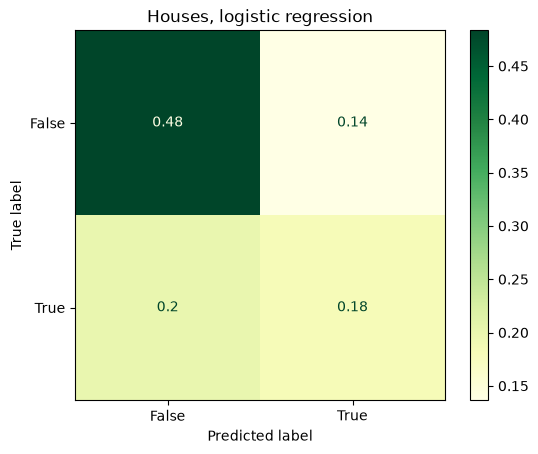

Accuracy : 0.664 | baseline: 0.62
Precision: 0.57
Recall   : 0.476
F1       : 0.519
AUC      : 0.687


In [56]:
y_hat = (p_best > 0.5).astype(int)          # yes/no with threshold t = 0.5
t, h = y_class[is_house], y_hat[is_house]   # truth and prediction, houses only

ConfusionMatrixDisplay.from_predictions(t, h, normalize="all", cmap=plt.cm.YlGn)
plt.title("Houses, logistic regression")
plt.show()

print("Accuracy :", round(accuracy_score(t, h), 3), "| baseline:", round(1 - t.mean(), 3))
print("Precision:", round(precision_score(t, h), 3))
print("Recall   :", round(recall_score(t, h), 3))
print("F1       :", round(f1_score(t, h), 3))
print("AUC      :", round(roc_auc_score(t, p_best[is_house]), 3))

**Result: the four boxes**
- **48%** of houses are fine, and the model says "no".
- **18%** are problem houses, and the model says "yes".
- **14%** are fine, but the model says "yes": the office would visit them for nothing.
- **20%** are problem houses, but the model says "no": they stay hidden.

**The measures**
- **Accuracy 0.66:** right in 66% of houses (48% + 18%). Saying "no" to everyone is already right 62% of the time,
  so the model is only a bit better on this measure (deck 12: compare accuracy with the baseline).
- **Precision 0.57:** when the model says "yes", it is right 57% of the time.
- **Recall 0.48:** of all real problem houses, the model finds about half.
- **F1 0.52:** precision and recall combined in one number.
- **AUC 0.69:** a random problem house gets a higher chance than a random fine house in 69% of cases
  (0.5 = guessing, 1 = perfect). Like our selection measure, AUC judges the **sorting**.

**What it means.** At threshold 0.5 the model misses more problem houses (20%) than it raises false alarms (14%):
it is a bit too cautious. This matters little for the office, because the office works down the sorted list
from the top instead of using a 0.5 cut.

### 4c. Competition: is our model better than the six regression models?

Our teammates' six models (linear regression, ridge and lasso, each with and without the expert rule)
predict the heating index as a number. Step by step:
1. For each fold, count the problem houses in the top 20%, for our model and for each regression model.
2. Subtract: **our model − regression model**, on the same houses. Positive = our model is better.
3. Average the differences over the 5 folds and compute the ± SE (how much chance alone could explain).

In [57]:
oof20 = pd.read_csv("../output/tables/task20_oof_predictions.csv")   # all 6 regression variants of task 20
log_folds = top20_per_fold(p_best)                                   # logistic regression, per fold

rows = []
for name in oof20.columns[4:]:                     # the 6 model columns (the first 4 are EGID, fold, house, y)
    reg_folds = top20_per_fold(oof20[name].to_numpy())
    diff = (log_folds - reg_folds) * 100           # difference per fold, in points
    rows.append({
        "regression model": name,
        "regression (%)": round(reg_folds.mean() * 100, 1),
        "logistic (%)": round(log_folds.mean() * 100, 1),
        "difference": round(diff.mean(), 1),
        "± SE": round(diff.std(ddof=1) / np.sqrt(5), 1),
        "logistic better in": f"{(diff > 0).sum()} of 5 folds",
        "AUC regression": round(roc_auc_score(t, oof20.loc[is_house, name]), 3),
    })
compare = pd.DataFrame(rows)
print("AUC logistic:", round(roc_auc_score(t, p_best[is_house]), 3))
compare

AUC logistic: 0.687


,regression model,regression (%),logistic (%),difference,± SE,logistic better in,AUC regression
0,"Linear regression, expert rule on",54.0,54.5,0.4,1.6,1 of 5 folds,0.684
1,"Linear regression, expert rule off",53.6,54.5,0.9,1.1,2 of 5 folds,0.686
2,"Ridge, expert rule on",54.5,54.5,0.0,3.7,2 of 5 folds,0.669
3,"Ridge, expert rule off",53.6,54.5,0.9,1.1,2 of 5 folds,0.686
4,"Lasso, expert rule on",54.0,54.5,0.4,1.6,1 of 5 folds,0.684
5,"Lasso, expert rule off",54.0,54.5,0.4,3.4,2 of 5 folds,0.664


**Result.** Our model is ahead by only **0.0 to 0.9 points**, less than one house per list. Chance alone could
cause differences of **1.1 to 3.7 points** (± SE), and our model wins in at most 2 of 5 folds.
The AUCs are all close (0.66–0.69).

**What it means.** Our model is **as good as** the six regression models, **but not better**.
Predicting "yes/no" sorts the houses just as well as predicting the number.

## 5. Save the results


In [58]:
out = pd.DataFrame({"EGID": train["EGID"], "fold": folds, "house": is_house, "y": y,
                    "Logistic regression": p_best})
out.to_csv("../output/tables/task21_oof_predictions.csv", index=False)   # probabilities per building
tuning.to_csv("../output/tables/task21_tuning.csv", index=False)         # the 12 settings
compare.to_csv("../output/tables/task21_vs_ridge.csv", index=False)      # fold-by-fold comparison

## 6. Interpretation

**Question.** Does treating the problem as classification (above 450 or not) rank houses better than
predicting the index with regression?

**Result.**
- The best logistic regression (C = 10, without the expert rule) puts **54.5%** houses above 450 into its
  top 20%, compared with **38%** for random choice and **45.1%** for the expert rule.
- The six regression models reach **53.6–54.5%**. The differences to logistic regression are
  between **0.0 and 0.9 points**, always smaller than their standard error (1.1–3.7).
- The AUC on houses is **0.687** for logistic regression and **0.664–0.686** for the regression models.
- As a yes/no rule (threshold 0.5), logistic regression classifies **66%** of houses correctly, only a little
  above the **62%** reached by always saying "not above 450". Of the houses it flags, **57%** are real problem
  houses (precision); it finds **48%** of all problem houses (recall).
- The penalty C hardly matters: all six values give 50–54.5%, within about one standard error.

**What this means.**
- Classification ranks houses **as well as regression, but not better**. Predicting the number or predicting
  "above 450 or not" leads to almost the same list. The limit is the information in the building register,
  not the choice of model.
- At the usual threshold of 0.5, the model misses more problem houses (20% of houses) than it raises false
  alarms (14%). The office does not need this threshold, because it works down the ranking from the top.

**Decision.** We keep a regression model as the main model, because it ranks houses
equally well and also gives an estimated index and an MAE that the office can read. Logistic regression is
reported as a comparison check.